# Deep Reinforcement Lerning Lectures - Policy Gradients

### Imports and auxiliary settings

In [5]:
# -------- OS / Colab detection --------
import os
import sys
import platform
import subprocess

OS_NAME = platform.system()   # "Windows", "Linux", "Darwin"
IN_COLAB = True

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    pass

print("OS:", OS_NAME, "| Colab:", IN_COLAB)

if IN_COLAB:
  !apt update
  !apt install -y xvfb x11-utils python3-opengl ffmpeg swig
  !pip install swig
  !pip install jax==0.7.2 jaxlib==0.7.2
  !pip install gymnasium==1.2.3 gymnasium[box2d] pyvirtualdisplay imageio-ffmpeg moviepy==1.0.3
  !pip install onnx==1.20.0 onnx2pytorch==0.5.3
  !pip install numpy==2.4.2

# -------- Device selection --------
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

OS: Linux | Colab: True
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:4 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]           
Get:5 https://cli.github.com/packages stable/main amd64 Packages [356 B]       
Hit:6 http://archive.ubuntu.com/ubuntu jammy InRelease                         
Get:7 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,599 kB]
Get:8 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]      
Get:9 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]        
Get:10 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [89.0 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [10.1 MB]  
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ub

In [6]:
%matplotlib inline

# PyTorch imports
import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Normal
from torch.utils.data import Dataset, DataLoader

# Cross-framework library for DL
import onnx
from onnx2pytorch import ConvertModel

# Auxiliary Python imports
import math
import io
import base64
import random
import shutil
import copy
import glob
from time import time, strftime, sleep
import numpy as np
from tqdm.notebook import tqdm

# Environment imports
import gymnasium as gym
from gymnasium.spaces import Box
from gymnasium import logger as gymlogger
from gymnasium.wrappers import RecordVideo
gymlogger.min_level = gymlogger.ERROR

# Plotting and notebook imports
import matplotlib.pyplot as plt
# import seaborn as sns; sns.set()
from IPython.display import HTML, display, clear_output

# -------- Virtual display (Linux / Colab only) --------
pydisplay = None

if OS_NAME == "Linux":
    try:
        from pyvirtualdisplay import Display
        pydisplay = Display(visible=0, size=(640, 480))
        pydisplay.start()
        print("Virtual display started.")
    except Exception as e:
        print("Skipping virtual display:", e)
else:
    print(f"Skipping virtual display on {OS_NAME} (not needed).")

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device = "cpu"
print("Device:", device)


Virtual display started.
Device: cuda


### Auxiliary Methods

In [7]:
class Logger(object):
    """Logger that can be used for debugging different values
    """
    def __init__(self, logdir, params=None, debug=False):
        self.gradients = []
        self.debug = debug
        self.basepath = os.path.join(logdir, strftime("%Y-%m-%dT%H-%M-%S"))
        os.makedirs(self.basepath, exist_ok=True)
        os.makedirs(self.log_dir, exist_ok=True)
        if params is not None and os.path.exists(params):
            shutil.copyfile(params, os.path.join(self.basepath, "params.pkl"))
        self.log_dict = {}
        self.dump_idx = {}

    def add_gradients(self, grad):
        if not self.debug: return
        self.gradients.append(grad)

    def compute_gradient_variance(self):
        vars_ = []
        grads_list = [np.zeros_like(self.gradients[0])] * 100
        for i, grads in enumerate(self.gradients):
            grads_list.append(grads)
            grads_list = grads_list[1:]
            grad_arr = np.stack(grads_list, axis=0)
            g = np.apply_along_axis(grad_variance, axis=-1, arr=grad_arr)
            vars_.append(np.mean(g))
        return vars_

    @property
    def param_file(self):
        return os.path.join(self.basepath, "params.pkl")

    @property
    def onnx_file(self):
        return os.path.join(self.basepath, "model.onnx")

    @property
    def video_dir(self):
        return os.path.join(self.basepath, "videos")

    @property
    def log_dir(self):
        return os.path.join(self.basepath, "logs")

    def log(self, name, value):
        if name not in self.log_dict:
            self.log_dict[name] = []
            self.dump_idx[name] = -1
        self.log_dict[name].append((len(self.log_dict[name]), time(), value))

    def get_values(self, name):
        if name in self.log_dict:
            return [x[2] for x in self.log_dict[name]]
        return None

    def dump(self):
        for name, rows in self.log_dict.items():
            with open(os.path.join(self.log_dir, name + ".log"), "a") as f:
                for i, row in enumerate(rows):
                    if i > self.dump_idx[name]:
                        f.write(",".join([str(x) for x in row]) + "\n")
                        self.dump_idx[name] = i

In [8]:
def wrap_env(env, logger, capture_video=True):
    # wrapper for recording
    env = gym.wrappers.RecordEpisodeStatistics(env)
    if capture_video:
        env = gym.wrappers.RecordVideo(env, logger.video_dir, episode_trigger=lambda idx: True)
    return env


def create_env(logger, env_id='BipedalWalker-v3', hardcore=False, capture_video=True):
    # initialize environment
    # env = wrap_env(gym.make(env_id, max_episode_steps=400, hardcore=hardcore, render_mode="rgb_array"),
    env = wrap_env(gym.make(env_id, max_episode_steps=1600, hardcore=hardcore, render_mode="rgb_array"),
                   logger=logger,
                   capture_video=capture_video)
    action_size = env.action_space.shape[0]
    state_size = env.observation_space.shape[0]
    return env, action_size, state_size


def set_seed(env, seed=None):
    # seeding the envrionment
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed(seed)
            torch.cuda.manual_seed_all(seed)


def transforms(state):
    # transofrm to numpy to tensor and push to device
    return torch.FloatTensor(state).to(device)


def test_environment(env, agent=None, seed=42, n_steps=200):
    # run and evaluate in the environment
    state, info = env.reset(seed=seed)
    for i in range(n_steps):
        env.render()

        if agent is None:
            action = env.action_space.sample()
        else:
            action, _ = agent.act(state)
            action = action.squeeze().cpu().numpy()
        state, reward, done, truncated, info = env.step(action)
        if done:
            state, info = env.reset(seed=seed)
    env.close()


def get_running_stat(stat, stat_len):
    # evaluate stats
    cum_sum = np.cumsum(np.insert(stat, 0, 0))
    return (cum_sum[stat_len:] - cum_sum[:-stat_len]) / stat_len


def plot_results(runner):
    # plot stats
    episode, r, l = np.array(runner.stats_rewards_list).T
    cum_r = get_running_stat(r, 10)
    cum_l = get_running_stat(l, 10)

    plt.figure(figsize=(16, 16))

    plt.subplot(321)

    # plot rewards
    plt.plot(episode[-len(cum_r):], cum_r)
    plt.plot(episode, r, alpha=0.5)
    plt.xlabel('Episode')
    plt.ylabel('Episode Reward')

    plt.subplot(322)

    # plot episode lengths
    plt.plot(episode[-len(cum_l):], cum_l)
    plt.plot(episode, l, alpha=0.5)
    plt.xlabel('Episode')
    plt.ylabel('Episode Length')

    plt.subplot(323)

    # plot return
    all_returns = np.array(runner.buffer.all_returns)
    plt.scatter(range(0, len(all_returns)), all_returns, alpha=0.5)
    mean_returns = np.array(runner.buffer.mean_returns)
    plt.plot(range(0, len(mean_returns)), mean_returns, color="orange")
    plt.xlabel('Episode')
    plt.ylabel('Return')

    plt.subplot(324)

    # plot entropy
    entropy_arr = np.array(runner.stats_entropy_list)
    plt.plot(range(0, len(entropy_arr)), entropy_arr)
    plt.xlabel('Episode')
    plt.ylabel('Entropy')

    plt.subplot(325)

    if runner.logger.debug:
        # plot variance
        variance_arr = np.array(runner.logger.compute_gradient_variance())
        plt.plot(range(0, len(variance_arr)), variance_arr)
        plt.xlabel('Episode')
        plt.ylabel('Variance')

    plt.show()


"""
Utility functions to enable video recording of gym environment and displaying it
"""
def show_video(logger):
    print(logger.video_dir)
    mp4list = glob.glob(f'{logger.video_dir}/*.mp4')
    if len(mp4list) > 0:
        mp4 = mp4list[0]
        video = io.open(mp4, 'r+b').read()
        encoded = base64.b64encode(video)
        display(HTML(data='''<video alt="test" autoplay
                  loop controls style="height: 400px;">
                  <source src="data:video/mp4;base64,{0}" type="video/mp4" />
                </video>'''.format(encoded.decode('ascii'))))
    else:
        print("Could not find video")


def grad_variance(g):
    # compute gradient variance
    return np.mean(g**2) - np.mean(g)**2

### Test environment

OpenAI offers a set of environments for Reinforcement Learning, which are accessible via the `gymnasium` pip package.
In this exercise we will focus on discrete control tasks using a Box2D simulation known as BipedalWalker-v3.
To access the Box2D packages, we use the gymnasium pypi `box2d` option.

In [9]:
# show behavior in envrionment with random agent
logger = Logger("logdir")
env, _, _ = create_env(logger)
test_environment(env)
show_video(logger)

/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


logdir/2026-04-30T13-02-50/videos


### Training Buffer

In [19]:
from torch.utils.data import Dataset, DataLoader

class Transition(object):
    """Transition helper object
    """
    def __init__(self, state, action, reward, next_state, log_probs):
        self.state = state
        self.action = action
        self.reward = reward
        self.next_state = next_state
        self.g_return = 0.0
        self.log_probs = log_probs


class Episode(object):
    """Class for collecting an episode of transitions
    """
    def __init__(self, discount):
        self.discount = discount
        self._empty()
        self.total_reward = 0.0

    def _empty(self):
        self.n = 0
        self.transitions = []

    def reset(self):
        self._empty()

    def size(self):
        return self.n

    def append(self, transition):
        self.transitions.append(transition)
        self.n += 1

    def states(self):
        return [s.state for s in self.transitions]

    def actions(self):
        return [a.action for a in self.transitions]

    def rewards(self):
        return [r.reward for r in self.transitions]

    def next_states(self):
        return [s_.next_state for s_ in self.transitions]

    def returns(self):
        return [r.g_return for r in self.transitions]

    def calculate_return(self):
        # calculate the return of the episode
        rewards = self.rewards()
        trajectory_len = len(rewards)
        # Convert rewards list to a PyTorch tensor
        rewards_tensor = torch.tensor(rewards, dtype=torch.float32)
        return_array = torch.zeros((trajectory_len,), dtype=torch.float32)
        g_return = torch.tensor(0.0, dtype=torch.float32) # Initialize g_return as a torch.Tensor
        discount_tensor = torch.tensor(self.discount, dtype=torch.float32, device=rewards_tensor.device) # Explicitly make discount a tensor
        for i in range(trajectory_len-1, -1, -1):
            g_return = rewards_tensor[i] + discount_tensor*g_return
            return_array[i] = g_return
            # Store the return value back into the transition, converting to a Python float
            self.transitions[i].g_return = g_return.item()
        return return_array


class BufferDataset(Dataset):
    """Buffer dataset used to iterate over buffer samples when training.
    """
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        t = self.data[idx]
        return t.state, t.action, t.reward, t.next_state, t.log_probs


class RolloutBuffer(object):
    # ===================================================
    # ++++++++++++++++++++ OPTIONAL +++++++++++++++++++++
    # ===================================================
    # > feel free to optimize sampling and buffer handling
    # ===================================================
    """Buffer to collect samples while
    ing out in the envrionment.
    """
    def __init__(self, capacity, batch_size, min_transitions):
        self.capacity = capacity
        self.batch_size = batch_size
        self.min_transitions = min_transitions
        self.buffer = []
        self._empty()
        self.mean_returns = []
        self.all_returns = []

    def _empty(self):
        # empty the buffer
        del self.buffer[:]
        self.position = 0

    def add(self, episode):
        # Saves a transition
        episode.calculate_return()
        for t in episode.transitions:
            if len(self.buffer) < self.capacity:
                self.buffer.append(None)
            self.buffer[self.position] = t
            self.position = (self.position + 1) % self.capacity

    def update_stats(self):
        # update the statistics on the buffer
        returns = [t.g_return for t in self.buffer]
        self.all_returns += returns
        mean_return = np.mean(np.array(returns))
        self.mean_returns += ([mean_return]*len(returns))

    def reset(self):
        # calls empty
        self._empty()

    def create_dataloader(self):
        # creates a dataloader for training
        train_loader = DataLoader(
            BufferDataset(self.buffer),
            batch_size=self.batch_size,
            shuffle=True
        )
        return train_loader

    def __len__(self):
        return len(self.buffer)

### Define Models

In [20]:
class ActorNet(nn.Module):
    """Actor network (policy)
    """
    def __init__(self, state_size, action_size, hidden_size):
        super(ActorNet, self).__init__()
        # ===================================================
        # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
        # ===================================================
        # 1) find a suitable architecture for the actor
        # ===================================================
        # pass

        self.fc1=nn.Linear(state_size, hidden_size)
        torch.nn.init.orthogonal_(self.fc1.weight, gain=math.sqrt(2))
        self.fc2=nn.Linear(hidden_size, hidden_size)
        torch.nn.init.orthogonal_(self.fc2.weight, gain=math.sqrt(2))
        self.mu=nn.Linear(hidden_size, action_size) # mean of gaussian distribution
        torch.nn.init.orthogonal_(self.mu.weight, gain=0.01)
        self.log_sigma=nn.Linear(hidden_size, action_size) # state dependent log sigma of gaussian distribution
        self.distribution = torch.distributions.Normal


    def forward(self, x):
        # ===================================================
        # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
        # ===================================================
        # 1) compute mu and sigma logit estimates
        # ===================================================
        y1=torch.tanh(self.fc1(x))
        y2=torch.tanh(self.fc2(y1))

        # mu_logits=self.distribution(self.mu(y2))
        mu_logits=self.mu(y2)
        # sigma_logits=self.distribution(self.log_sigma(y2))
        sigma_logits=self.log_sigma(y2)
        sigma_logits=torch.clamp(sigma_logits, -20, 2)
        return mu_logits, sigma_logits # must return this!


class CriticNet(nn.Module):
    """Critic network computing the state value
    """
    def __init__(self, state_size, action_size, hidden_size):
        super(CriticNet, self).__init__()
        # ===================================================
        # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
        # ===================================================
        # 1) find a suitable architecture for the critic
        # ===================================================

        self.fc1=nn.Linear(state_size, hidden_size)
        torch.nn.init.orthogonal_(self.fc1.weight, gain=math.sqrt(2))
        self.fc2=nn.Linear(hidden_size, hidden_size)
        torch.nn.init.orthogonal_(self.fc2.weight, gain=math.sqrt(2))
        self.value=nn.Linear(hidden_size, 1) # output state value
        torch.nn.init.orthogonal_(self.value.weight, gain=1.0)

        #pass

    def forward(self, x):
        # ===================================================
        # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
        # ===================================================
        # 1) compute the value estimates
        # ===================================================
        y1=torch.tanh(self.fc1(x))
        y2=torch.tanh(self.fc2(y1))
        value=self.value(y2).view(-1)
        return value
        # pass


class ActorCriticNet(nn.Module):
    """Combining both networks and add helper methods to act and evaluate samples.
    """
    def __init__(self, state_size, action_size, hidden_size):
        super(ActorCriticNet, self).__init__()
        # ===================================================
        # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
        # ===================================================
        # 1) initialize your networks
        # ===================================================
        self.actor = ActorNet(state_size, action_size, hidden_size)
        self.critic = CriticNet(state_size, action_size, hidden_size)
        # pass

    def forward(self, x):
        x = x.reshape(1, -1)
        return self.act(x)

    def act(self, state):
        # ===================================================
        # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
        # ===================================================
        # 1) get mean and sigma logits
        # 2) softplus the sigma logits to ensure only positive values (add some eps value to avoid 0 probabilities)
        # 3) create a Normal distribution based on mu and sigma
        # 4) sample from the distribution
        # 5) get log probabilities
        # ===================================================
        mu_logits, sigma_logits = self.actor(state)
        sigma = torch.nn.functional.softplus(sigma_logits) + 1e-5
        dist = self.actor.distribution(mu_logits, sigma)
        action = dist.sample()
        log_probs = dist.log_prob(action).sum(dim=-1)
        return action, log_probs
        # pass

    def evaluate(self, state, action):
        # ===================================================
        # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
        # ===================================================
        # 1) get mean and sigma logits
        # 2) softplus the sigma logits to ensure only positive values (add some eps value to avoid 0 probabilities)
        # 3) create a Normal distribution based on mu and sigma
        # 4) get log probabilities
        # 5) get entropy from the distribution
        # 6) evaluate state value
        # ===================================================
        mu_logits, sigma_logits = self.actor(state)
        
        mu_logits = torch.nan_to_num(mu_logits, 0.0)
        sigma_logits = torch.nan_to_num(sigma_logits, 0.0)
        
        sigma = torch.nn.functional.softplus(sigma_logits) + 1e-5

        sigma = torch.clamp(sigma, 1e-4, 1.0)
        
        dist = self.actor.distribution(mu_logits, sigma)
        log_probs = dist.log_prob(action).sum(dim=-1)
        entropy = dist.entropy().sum(dim=-1)
        value = self.critic(state)
        return log_probs, entropy, value
        # pass

### Define Agent

In [21]:
class Agent(object):
    """Agent class used for training, saving data and handling the model.
    """
    def __init__(self, buffer, state_size, action_size, hidden_size, learning_rate, logger, eps_clip, n_epochs,
                 weight_decay, betas, loss_scales, discount, checkpoint_dir="ckpts"):
        self.action_size = action_size
        self.state_size = state_size
        self.buffer = buffer
        self.checkpoint_dir = checkpoint_dir
        self.loss_scales = loss_scales
        self.n_epochs = n_epochs
        self.eps_clip = eps_clip
        self.logger = logger
        self.discount = discount
        # ===================================================
        # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
        # ===================================================
        # 1) initialize ActorCriticNet instance
        # 2) create initializers
        # ===================================================
        self.model = ActorCriticNet(state_size, action_size, hidden_size).to(device)
        self.optimizer = optim.Adam(self.model.parameters(), lr=learning_rate, weight_decay=weight_decay, betas=betas)
        # pass


    def save_checkpoint(self, epoch, info=''):
        """Saves a model checkpoint"""
        state = {
            'info': info,
            'epoch': epoch,
            'state_dict': self.model.state_dict(),
            'optimizer': self.optimizer.state_dict()
        }
        os.makedirs(self.checkpoint_dir, exist_ok=True)
        ckp_name = 'best-checkpoint.pth' if info == 'best' else f'checkpoint-epoch{epoch}.pth'
        filename = os.path.join(self.checkpoint_dir, ckp_name)
        torch.save(state, filename)

    def resume_checkpoint(self, resume_path):
        """Resumes training from an existing model checkpoint"""
        print("Loading checkpoint: {} ...".format(resume_path))
        checkpoint = torch.load(resume_path)
        # load architecture params from checkpoint.
        self.model.load_state_dict(checkpoint['state_dict'])
        # load optimizer state from checkpoint only when optimizer type is not changed.
        self.optimizer.load_state_dict(checkpoint['optimizer'])
        print("Checkpoint loaded. Resume training")

    def load_onnx_checkpoint(self, onnx_file):
        self.model.actor = ConvertModel(onnx.load(onnx_file)).to(device)
        self.model.eval()

    def save_onnx_checkpoint(self):
        """Create an ONNX checkpoint"""
        dummy_input = torch.randn((1, self.state_size))
        dummy_input_t = transforms(dummy_input).to(device)
        model = agent.model.actor.to(device)
        torch.onnx.export(model, dummy_input_t, "submission_actor.onnx", verbose=False, opset_version=10, export_params=True, do_constant_folding=True)

    def check(self, file_name):
        # Load the ONNX model
        model = onnx.load(file_name)
        # Check that the IR is well formed
        onnx.checker.check_model(model)

    def act(self, state):
        # ===================================================
        # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
        # ===================================================
        # 1) prepare state tensors
        # 2) check if shape is ok or expand acordingly
        # 3) get action and log probabilities
        # ===================================================
        # get action probs then sample from the probabilities
        if not isinstance(state, torch.Tensor):
            # state = transforms(state).to(device)
            state = transforms(state).to(device).float()
        if len(state.shape) == 1:
            state = state.unsqueeze(0)
        action, log_probs = self.model.act(state)
        action_for_env = action.cpu().detach().numpy().flatten()
        # action_np = action.detach().cpu().numpy().flatten()   # shape (action_size,)
        return action_for_env, log_probs.detach()
        # pass

    def train(self):
        for i in range(self.n_epochs):
            # create the a dataloader based on the current buffer
            loader = self.buffer.create_dataloader()
            # iterate over the samples in the dataloader
            for states, actions, rewards, next_states, old_log_probs in loader:
                # ===================================================
                # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
                # ===================================================
                # 1) compute target value with next state and reward
                # 2) compute advantage function from target and current state and action
                # 3) compute importance sampling ratio from log probabilities
                # 4) compute surrogate loss with the advantage and clipped surrogate loss
                # 5) compute value losses
                # 6) compute total loss with entropy regularization
                # 7) compute gradients and perform optimization step
                # ===================================================
                # states = states.to(device)
                # actions = actions.to(device)
                # rewards = rewards.to(device)
                # next_states = next_states.to(device)
                # old_log_probs = old_log_probs.to(device)
                states = states.to(device).float()
                actions = actions.to(device).float()
                rewards = rewards.to(device).float()
                next_states = next_states.to(device).float()
                old_log_probs = old_log_probs.to(device).float()
                with torch.no_grad():
                    value_next = self.model.critic(next_states)
                    target_values = value_next * self.discount + rewards
                    
                    target_values = torch.clamp(target_values, -1e3, 1e3)


                log_probs, entropy, values = self.model.evaluate(states, actions)
                advantages = target_values - values
                std = advantages.std()
                # advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

                if std>1e-8:
                    advantages = (advantages - advantages.mean()) / (std + 1e-8)
                else:
                    advantages = advantages - advantages.mean()
                


                ratios = torch.exp(log_probs - old_log_probs)

                surrogate1 = ratios * advantages
                surrogate2 = torch.clamp(ratios, 1 - self.eps_clip, 1 + self.eps_clip) * advantages
                policy_loss = -torch.min(surrogate1, surrogate2).mean()


                value_loss = F.mse_loss(values, target_values)


                loss = self.loss_scales[0] * policy_loss + self.loss_scales[1] * value_loss - self.loss_scales[2] * entropy.mean()

                self.optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 0.5)
                self.optimizer.step()
                #pass

        # return losses and entropy
        return (loss.mean().detach().cpu().numpy(),
                value_loss.mean().detach().cpu().numpy(),
                policy_loss.mean().detach().cpu().numpy()), entropy.mean().detach().cpu().numpy()

### Define Task Runner

In [22]:
class Runner(object):
    """Runner class performing the rollout in the environment and calling the agent training function periodically
    """
    def __init__(self, env, agent, buffer, logger, discount=0.99, n_episodes=4000, reward_scale=lambda x: x,
                 use_buffer_reset=True, stats_interval=1, print_stats=True, min_average_reward=300, render=False, seed=42, checkpoint_interval=100, max_episode_steps=2000):
        self.env = env
        self.agent = agent
        self.buffer = buffer
        self.render = render
        self.logger = logger
        self.discount = discount
        self.n_episodes = n_episodes
        self.reward_scale = reward_scale
        self.use_buffer_reset = use_buffer_reset
        self.stats_interval = stats_interval
        self.print_stats = print_stats
        self.min_average_reward = min_average_reward
        self.seed = seed
        self.max_episode_steps = max_episode_steps
        # store stats for plotting
        self.stats_rewards_list = []
        self.stats_entropy_list = []
        # stats for running episodes
        self.timesteps = 0
        self.checkpoint_interval = checkpoint_interval
        self.best_model = None
        self.max_reward = -np.inf
        self.successful_episodes = 0 # Initialize a counter for successful episodes

    def run(self):
        self.agent.model.eval()
        # train for n episodes
        with tqdm(range(self.n_episodes)) as pbar:
            for e in pbar:
                # reset env and stats
                state, info = self.env.reset(seed=self.seed)
                total_losses = 0.
                value_losses = 0.
                policy_losses = 0.

                # create new episode
                episode = Episode(discount=self.discount)

                # save model
                if e % self.checkpoint_interval == 0:
                    self.agent.save_checkpoint(e)

                done = False
                # train in each episode until episode is done
                while not done:
                    self.timesteps += 1
                    # render env
                    if self.render: self.env.render()

                    # ===================================================
                    # ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
                    # ===================================================
                    # 1) get action and log_probs
                    # 2) step in the environment to collect transitions
                    # 3) uptade agent when buffer has sufficient samples
                    # 4) log statistics and reset buffer
                    # ===================================================
                    action_raw, log_probs = self.agent.act(state)
                    # print(f"Action shape: {action.shape}")
                    action = np.clip(action_raw, -1.0, 1.0)   # if action is numpy array)
                    next_state, reward, terminated, truncated, info = self.env.step(action)
                    done = terminated or truncated
                    reward = self.reward_scale(reward)
                    episode.total_reward += reward

                    transition = Transition(state, action, reward, next_state, log_probs)

                    episode.append(transition)
                    # if e % 100 == 0:
                    #     print(f"Episode {e}, timesteps {self.timesteps}, reward so far: {episode.total_reward}")
                self.buffer.add(episode)
                
                
                # Always update the progress bar description with episode and reward
                pbar_description = f"Episode {e} | Reward: {episode.total_reward:.2f}"
                
                # print(len(self.buffer), self.buffer.min_transitions)
                # print(f"Step {self.timesteps} | Action: {action} | Done: {done} | Reward: {reward}")
                
                if len(self.buffer) >= self.buffer.min_transitions:
                    total_losses, entropy = self.agent.train()
                    self.buffer.update_stats()
                    if self.use_buffer_reset:
                        self.buffer.reset()
                    self.stats_entropy_list.append(entropy)
                    self.stats_rewards_list.append((e, episode.total_reward, episode.size()))

                    # Calculate and log success rate (accuracy)
                    is_successful = 1 if episode.total_reward >= self.min_average_reward else 0
                    self.successful_episodes += is_successful
                    # Avoid division by zero if starting episodes from 0
                    current_episode_count = e + 1
                    success_rate = self.successful_episodes / current_episode_count
                    self.logger.log("success_rate", success_rate)

                    if self.print_stats and e % self.stats_interval == 0:
                        pbar_description = f"Episode {e} | Reward: {episode.total_reward:.2f} | Loss: {total_losses[0]:.4f} | Value Loss: {total_losses[1]:.4f} | Policy Loss: {total_losses[2]:.4f} | Entropy: {entropy:.4f} | Success Rate: {success_rate:.2f}"
                    self.logger.log("reward", episode.total_reward)
                    self.logger.log("loss", total_losses[0])
                    self.logger.log("value_loss", total_losses[1])
                    self.logger.log("policy_loss", total_losses[2])
                    self.logger.log("entropy", entropy)
                    self.logger.dump()

                pbar.set_description(pbar_description)
                # print(f"Episode {e} finished after {episode.size()} steps")
                
                # save best model
                if self.best_model is None or episode.total_reward > self.max_reward:
                    self.best_model = copy.deepcopy(self.agent.model)
                    self.agent.save_checkpoint(e, 'best')
                    self.max_reward = episode.total_reward

### Train Agent

This is a where you run your actor-critic PPO algorithm.

Some tips as to what you need to implement:
- chose proper architectures for the actor-critic networks
- choose the appropriate loss function (think on which kind of problem you are solving)
- choose an optimizer and its hyper-parameters
- optional: use a learning-rate scheduler
- store your model and training progress often so you don't loose progress if your program crashes

In case you use the provided Logger:
- `logger.log("training_loss", <loss-value>)` to log a particular value
- `logger.dump()` to write the current logs to a log file (e.g. after every episode)
- `logger.log_dir`, `logger.param_file`, `logger.onnx_file`, `logger.video_dir` point to files or directories you can use to save files
- you might want to specify your google drive folder as a logdir in order to automatically sync your results
- if you log the metrics specified in the `plot_metrics` function you can use it to visualize your training progress (or take it as a template to plot your own metrics)

In [23]:
# create environment
logger = Logger("logdir")
env, action_size, state_size = create_env(logger, capture_video=False)

seed = 31
# set seed
set_seed(env, seed=seed)

# ===================================================
# ++++++++++++++++ YOUR CODE HERE +++++++++++++++++++
# ===================================================
# > find suitable hyperparameters
# hyperparameters
episodes = 3000 # run agent for this many episodes
epochs = 10 # run n epochs of network updates
hidden_size = 64 # number of units in NN hidden layers
learning_rate = 3e-4 # learning rate for optimizer
discount = 0.99 # discount factor gamma value
reward_scale = lambda x: x # reward scaling

batch_size = 64 # number of samples used for an update
min_transitions = 2000 # number of minimum transitions until update is triggered
capacity = 100000 # maximum number of transitions stored in the rollout buffer

use_buffer_reset = True # resets the buffer after every update
eps_clip = 0.2 # clipping or importance sampling updates
loss_scales = (1.0, 1.0, 0.1) # loss scales (value loss, policy loss, entropy loss)
betas = (0.9, 0.999) # optimizer beta parameters
weight_decay = 1e-5 # optimizer weight decay
checkpoint_interval = 100 # checkpoint interval to overwrite the parameters

# additional settings
print_stats = True
render = True

In [24]:
buffer = RolloutBuffer(capacity=capacity, batch_size=batch_size, min_transitions=min_transitions)
agent = Agent(buffer=buffer, state_size=state_size, action_size=action_size, hidden_size=hidden_size,
              learning_rate=learning_rate, logger=logger, eps_clip=eps_clip, n_epochs=epochs, weight_decay=weight_decay, betas=betas, loss_scales=loss_scales, discount=discount)
runner = Runner(env=env, agent=agent, buffer=buffer, logger=logger, discount=discount, n_episodes=episodes, reward_scale=reward_scale,
                use_buffer_reset=use_buffer_reset, print_stats=print_stats, render=render, seed=seed)

In [25]:
import os
checkpoint_dir = "ckpts"  # or whatever you used
print(os.listdir(checkpoint_dir))

['checkpoint-epoch400.pth', 'checkpoint-epoch0.pth', 'checkpoint-epoch100.pth', 'checkpoint-epoch700.pth', 'best-checkpoint.pth', 'checkpoint-epoch500.pth', 'checkpoint-epoch300.pth', 'checkpoint-epoch800.pth', 'checkpoint-epoch200.pth', 'checkpoint-epoch600.pth']


In [26]:
runner.run()

  0%|          | 0/3000 [00:00<?, ?it/s]

/tmp/ipykernel_57/2693515719.py:122: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1857.)
  std = advantages.std()


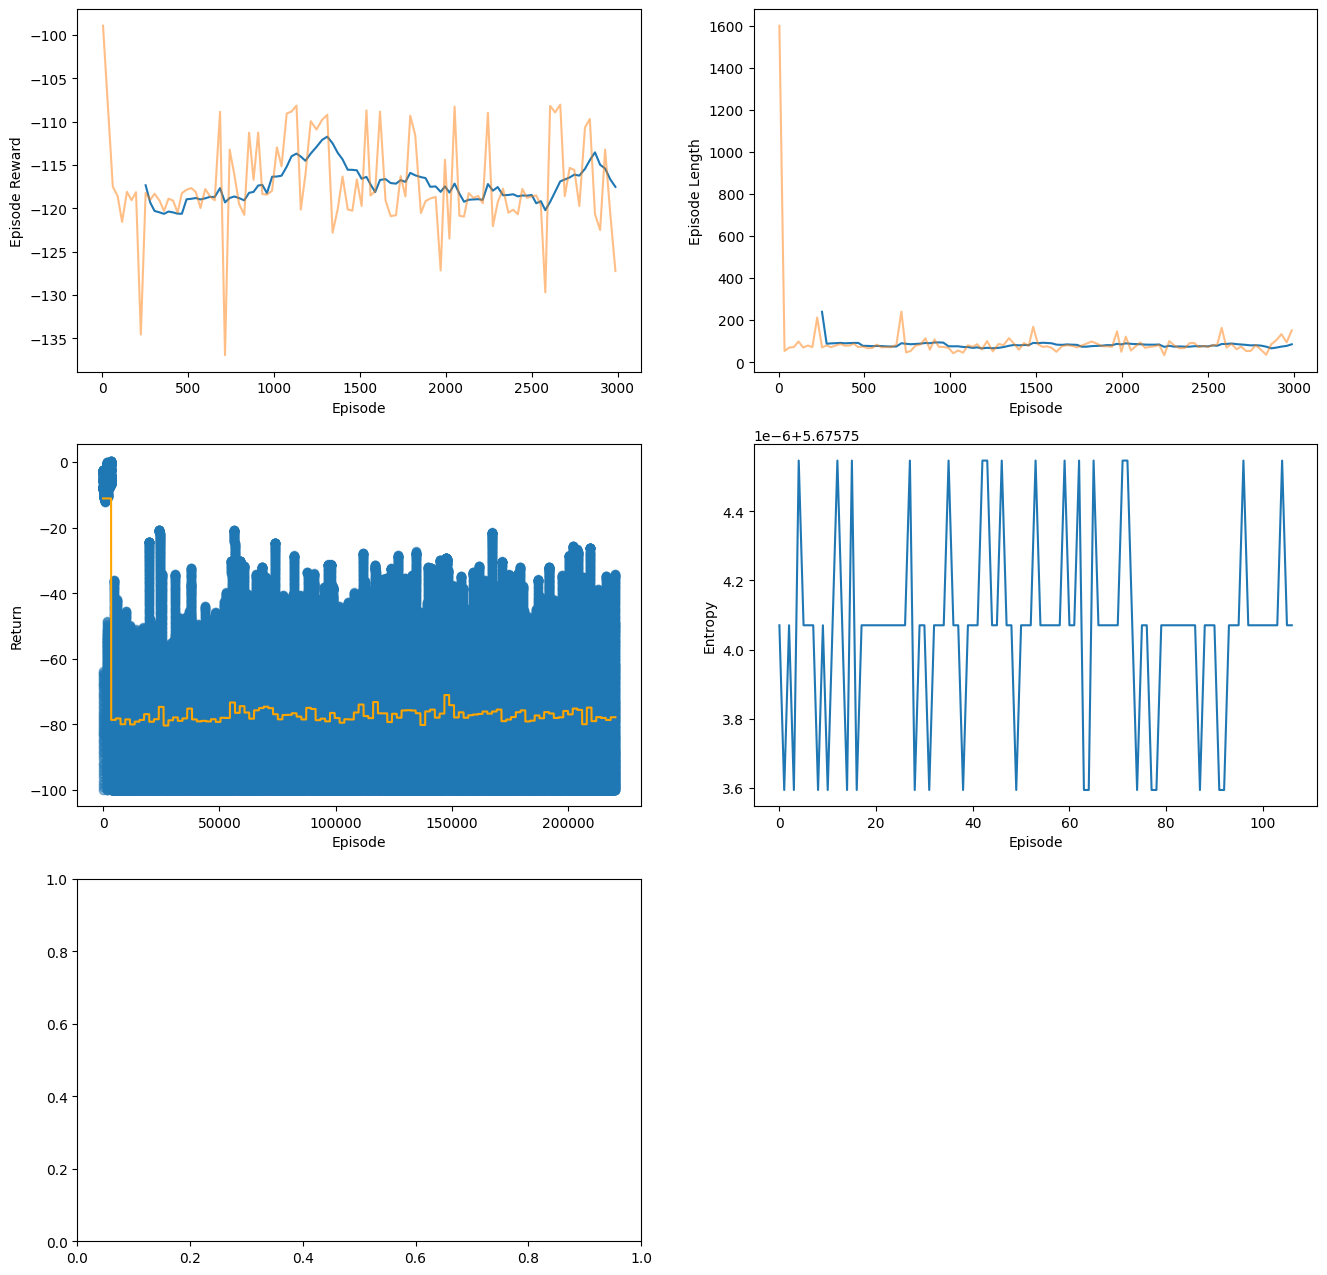

In [28]:
plot_results(runner)

In [ ]:
agent.save_onnx_checkpoint()

## Visualize Agent

In [ ]:
# load model from checkpoint
agent.resume_checkpoint('ckpts/best-checkpoint.pth')

In [ ]:
# run agent in the envrionment
env, _, _ = create_env(logger)
agent.model.eval()
test_environment(env=env, agent=agent)
show_video(logger)

# Demo Evaluations

In [ ]:
agent.load_onnx_checkpoint('demo.onnx')

In [ ]:
# run agent in the envrionment
logger = Logger('logdir')
env, _, _ = create_env(logger)
agent.model.eval()
test_environment(env=env, agent=agent, n_steps=500)
show_video(logger)